In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the dataset

df = pd.read_csv("../data/creditcard.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (284807, 31)


In [4]:
import os

print(os.getcwd())

c:\Users\User\Desktop\Projects\Personal_Projects\104_Internship_CybersNova\Credit-Card-Fraud-Detection\notebooks


In [5]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (284807, 31)


In [6]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
# Basic information about the dataset

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14    

In [8]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum().sum())

Missing values in each column:
0


In [9]:
# Statistical summary

df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [10]:
# Count normal and fraudulent transactions

class_counts = df["Class"].value_counts()

print("Transaction Class Distribution:")
print(class_counts)

print("\nClass Percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Transaction Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


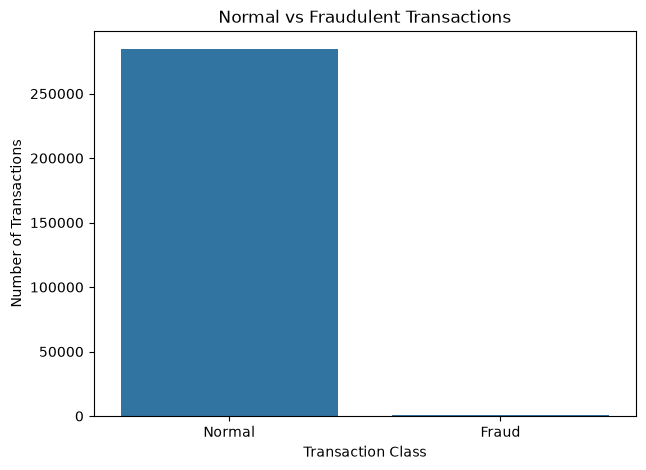

In [11]:
# Visualize class distribution

plt.figure(figsize=(7, 5))

sns.countplot(x="Class", data=df)

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()

In [12]:
# Compare transaction amounts by class

print("Average Transaction Amount:")
print(df.groupby("Class")["Amount"].mean())

print("\nMedian Transaction Amount:")
print(df.groupby("Class")["Amount"].median())

print("\nMaximum Transaction Amount:")
print(df.groupby("Class")["Amount"].max())

Average Transaction Amount:
Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64

Median Transaction Amount:
Class
0    22.00
1     9.25
Name: Amount, dtype: float64

Maximum Transaction Amount:
Class
0    25691.16
1     2125.87
Name: Amount, dtype: float64


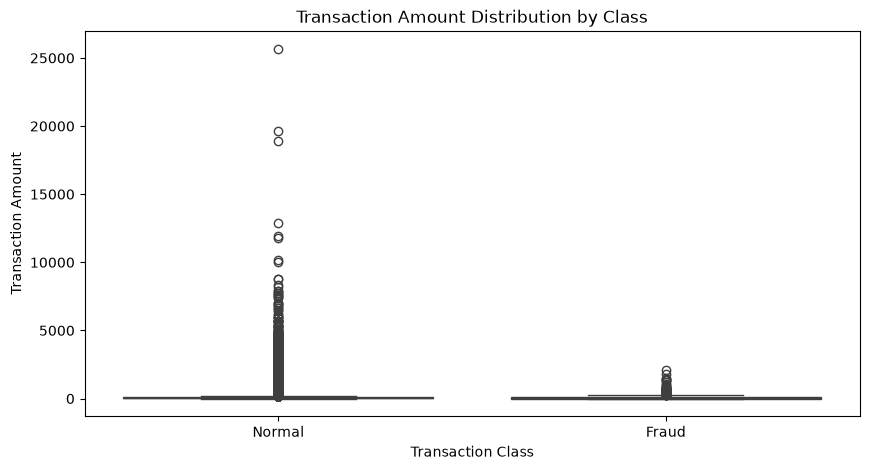

In [13]:
# Distribution of transaction amounts

plt.figure(figsize=(10, 5))

sns.boxplot(x="Class", y="Amount", data=df)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()

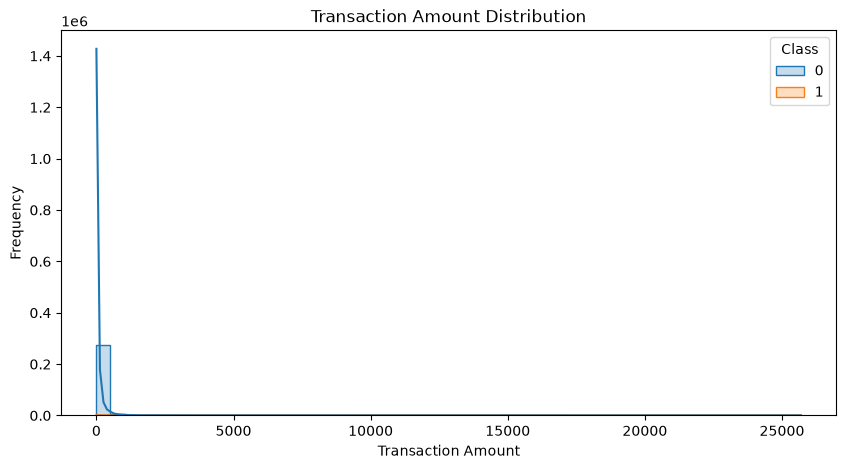

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    kde=True,
    element="step"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

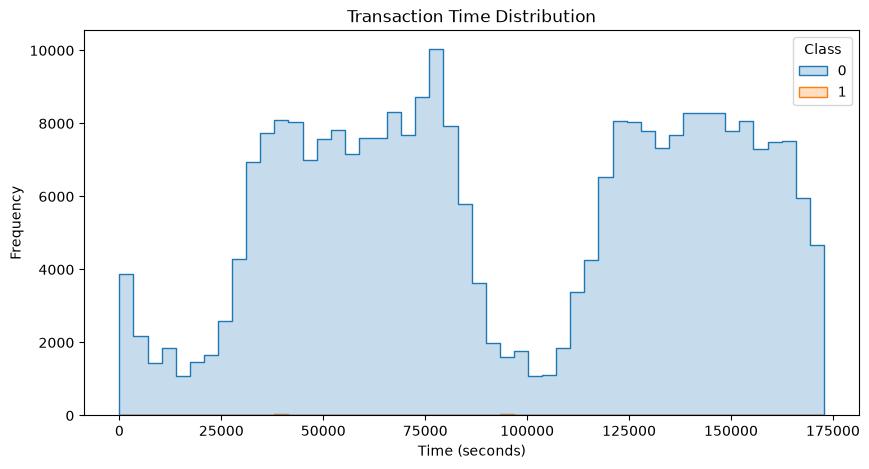

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=50,
    element="step"
)

plt.title("Transaction Time Distribution")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency")

plt.show()

In [16]:
correlation = df.corr(numeric_only=True)["Class"].sort_values(ascending=False)

print("Correlation of features with Class:")
print(correlation)

Correlation of features with Class:
Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


In [17]:
# Separate features and target

X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training set: (227845, 30)
Testing set: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test_scaled[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Feature scaling completed!")

Feature scaling completed!


In [20]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

print("Baseline Logistic Regression trained successfully!")

Baseline Logistic Regression trained successfully!


In [21]:
y_pred_baseline = baseline_model.predict(X_test_scaled)
y_prob_baseline = baseline_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred_baseline)
precision = precision_score(y_test, y_pred_baseline)
recall = recall_score(y_test, y_pred_baseline)
f1 = f1_score(y_test, y_pred_baseline)
roc_auc = roc_auc_score(y_test, y_prob_baseline)

print("Baseline Logistic Regression Results")
print("------------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Baseline Logistic Regression Results
------------------------------------
Accuracy : 0.9992
Precision: 0.8289
Recall   : 0.6429
F1-Score : 0.7241
ROC-AUC  : 0.9559


In [23]:
print("Classification Report:")
print(classification_report(y_test, y_pred_baseline))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



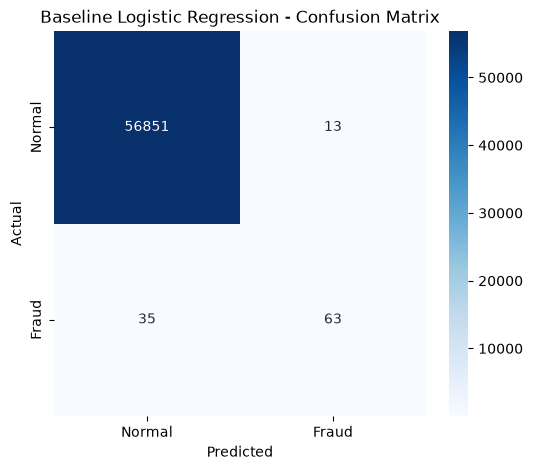

In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [25]:
# Logistic Regression with class weighting

balanced_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

balanced_model.fit(X_train_scaled, y_train)

print("Class-weighted Logistic Regression trained successfully!")

Class-weighted Logistic Regression trained successfully!


In [26]:
# Predictions from the balanced model

y_pred_balanced = balanced_model.predict(X_test_scaled)
y_prob_balanced = balanced_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [27]:
# Evaluate the class-weighted model

accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
precision_balanced = precision_score(y_test, y_pred_balanced)
recall_balanced = recall_score(y_test, y_pred_balanced)
f1_balanced = f1_score(y_test, y_pred_balanced)
roc_auc_balanced = roc_auc_score(y_test, y_prob_balanced)

print("Class-Weighted Logistic Regression Results")
print("------------------------------------------")
print(f"Accuracy : {accuracy_balanced:.4f}")
print(f"Precision: {precision_balanced:.4f}")
print(f"Recall   : {recall_balanced:.4f}")
print(f"F1-Score : {f1_balanced:.4f}")
print(f"ROC-AUC  : {roc_auc_balanced:.4f}")


Class-Weighted Logistic Regression Results
------------------------------------------
Accuracy : 0.9755
Precision: 0.0610
Recall   : 0.9184
F1-Score : 0.1144
ROC-AUC  : 0.9722


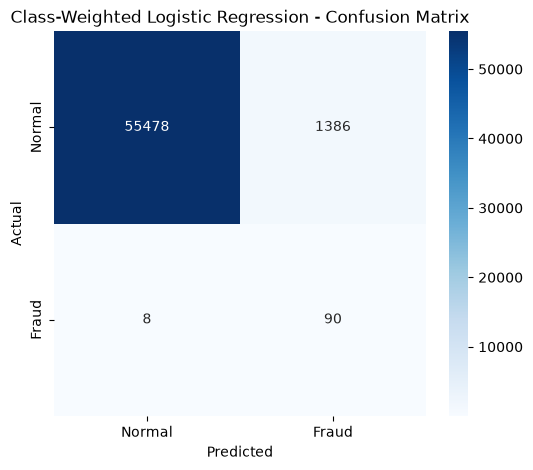

In [28]:
# Confusion Matrix

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Class-Weighted Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [29]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Original training data:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nOriginal shape:", X_train_scaled.shape)
print("SMOTE shape:", X_train_smote.shape)

Original training data:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Original shape: (227845, 30)
SMOTE shape: (454902, 30)


In [30]:
# Train Logistic Regression on SMOTE-balanced data

smote_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_model.fit(X_train_smote, y_train_smote)

print("SMOTE Logistic Regression trained successfully!")

SMOTE Logistic Regression trained successfully!


In [31]:
# Predictions

y_pred_smote = smote_model.predict(X_test_scaled)
y_prob_smote = smote_model.predict_proba(X_test_scaled)[:, 1]

print("SMOTE model predictions generated successfully!")

SMOTE model predictions generated successfully!


In [32]:
# Evaluate the SMOTE model

accuracy_smote = accuracy_score(y_test, y_pred_smote)
precision_smote = precision_score(y_test, y_pred_smote)
recall_smote = recall_score(y_test, y_pred_smote)
f1_smote = f1_score(y_test, y_pred_smote)
roc_auc_smote = roc_auc_score(y_test, y_prob_smote)

print("SMOTE Logistic Regression Results")
print("--------------------------------")
print(f"Accuracy : {accuracy_smote:.4f}")
print(f"Precision: {precision_smote:.4f}")
print(f"Recall   : {recall_smote:.4f}")
print(f"F1-Score : {f1_smote:.4f}")
print(f"ROC-AUC  : {roc_auc_smote:.4f}")

SMOTE Logistic Regression Results
--------------------------------
Accuracy : 0.9742
Precision: 0.0580
Recall   : 0.9184
F1-Score : 0.1092
ROC-AUC  : 0.9699


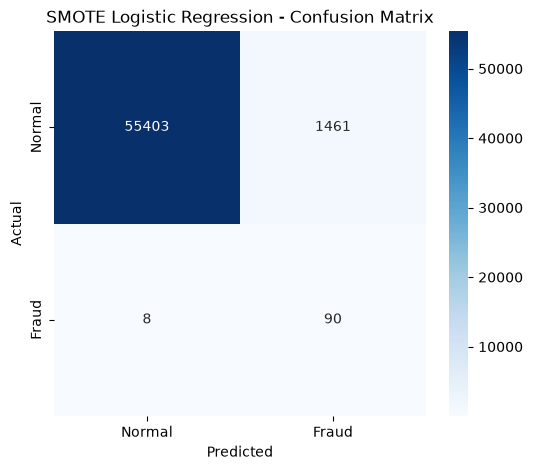

In [33]:
# Confusion Matrix

cm_smote = confusion_matrix(y_test, y_pred_smote)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_smote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("SMOTE Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [35]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

Random Forest Results
---------------------
Accuracy : 0.9995
Precision: 0.9059
Recall   : 0.7857
F1-Score : 0.8415
ROC-AUC  : 0.9573


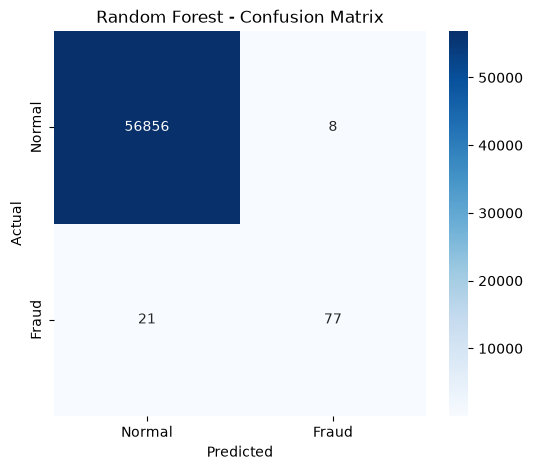

In [36]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [37]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_scaled.columns
).sort_values(ascending=False)

print(feature_importance.head(10))

V14    0.191038
V10    0.106849
V4     0.105643
V12    0.097603
V17    0.090339
V3     0.065919
V11    0.046342
V16    0.044655
V2     0.038335
V9     0.025445
dtype: float64


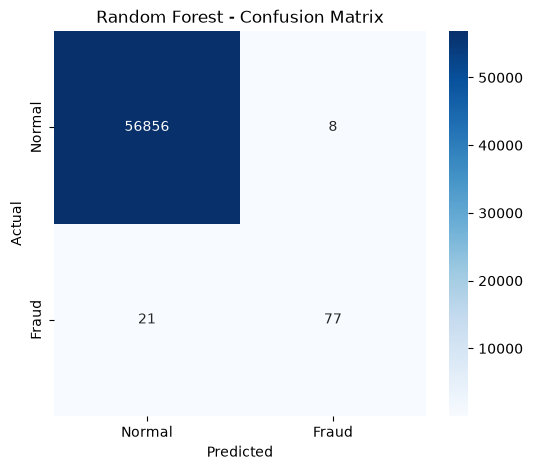

In [38]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

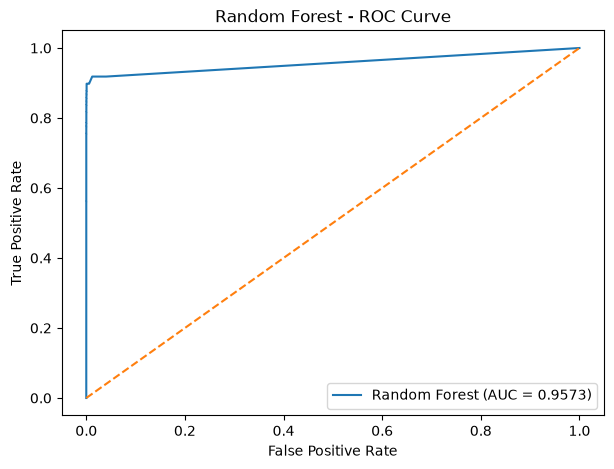

In [39]:
from sklearn.metrics import roc_curve, precision_recall_curve

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_rf:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.show()

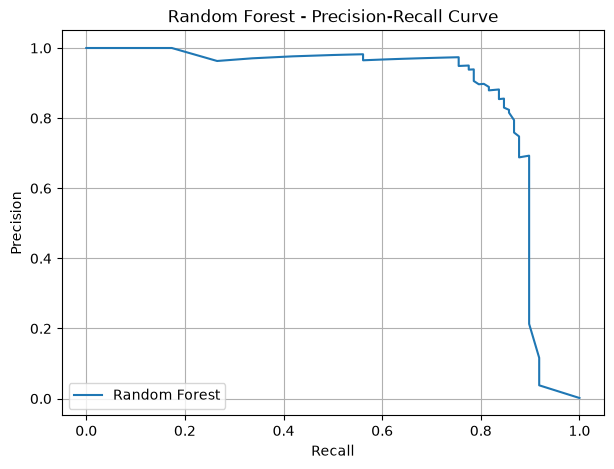

In [40]:
precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_curve,
    precision_curve,
    label="Random Forest"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

In [41]:
import numpy as np

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

print("Threshold Analysis")
print("------------------")

for threshold in thresholds:
    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold Analysis
------------------
Threshold: 0.1 | Precision: 0.5752 | Recall: 0.8980 | F1: 0.7012
Threshold: 0.2 | Precision: 0.7167 | Recall: 0.8776 | F1: 0.7890
Threshold: 0.3 | Precision: 0.8300 | Recall: 0.8469 | F1: 0.8384
Threshold: 0.4 | Precision: 0.8804 | Recall: 0.8265 | F1: 0.8526
Threshold: 0.5 | Precision: 0.8966 | Recall: 0.7959 | F1: 0.8432


In [42]:
final_threshold = 0.4

y_pred_final = (y_prob_rf >= final_threshold).astype(int)

cm_final = confusion_matrix(y_test, y_pred_final)

print("Final Confusion Matrix - Threshold 0.4")
print(cm_final)

Final Confusion Matrix - Threshold 0.4
[[56853    11]
 [   17    81]]


In [43]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "../models/random_forest_fraud_model.pkl")
joblib.dump(scaler, "../models/transaction_scaler.pkl")

print("Final model and scaler saved successfully!")

Final model and scaler saved successfully!


In [44]:
import joblib
import numpy as np

# Load saved model and scaler
loaded_model = joblib.load("../models/random_forest_fraud_model.pkl")
loaded_scaler = joblib.load("../models/transaction_scaler.pkl")

FINAL_THRESHOLD = 0.4

def predict_fraud(transaction):
    """
    Predict whether a transaction is normal or fraudulent.

    transaction must contain:
    Time, V1-V28, Amount
    """

    transaction = transaction.copy()

    # Scale Time and Amount
    transaction[["Time", "Amount"]] = loaded_scaler.transform(
        transaction[["Time", "Amount"]]
    )

    # Get fraud probability
    fraud_probability = loaded_model.predict_proba(transaction)[:, 1][0]

    # Apply final threshold
    prediction = int(fraud_probability >= FINAL_THRESHOLD)

    if prediction == 1:
        result = "Fraud"
    else:
        result = "Normal"

    return result, fraud_probability

print("Prediction function created successfully!")

Prediction function created successfully!


In [45]:
# Take one transaction from the test set
sample_transaction = X_test.iloc[[0]].copy()

# Get actual label
actual_label = y_test.iloc[0]

# Predict
prediction, probability = predict_fraud(sample_transaction)

print("Actual Class      :", "Fraud" if actual_label == 1 else "Normal")
print("Predicted Class   :", prediction)
print(f"Fraud Probability : {probability:.4f}")

Actual Class      : Normal
Predicted Class   : Normal
Fraud Probability : 0.0000


In [46]:
# Find one actual fraud transaction from the test set
fraud_indices = y_test[y_test == 1].index

fraud_sample = X_test.loc[[fraud_indices[0]]]
actual_label = y_test.loc[fraud_indices[0]]

# Predict
prediction, probability = predict_fraud(fraud_sample)

print("Actual Class      :", "Fraud" if actual_label == 1 else "Normal")
print("Predicted Class   :", prediction)
print(f"Fraud Probability : {probability:.4f}")

Actual Class      : Fraud
Predicted Class   : Fraud
Fraud Probability : 0.9700


In [47]:
df = pd.read_csv("../data/creditcard.csv")

In [48]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nClass distribution:")
print(df["Class"].value_counts())

Dataset shape: (284807, 31)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2

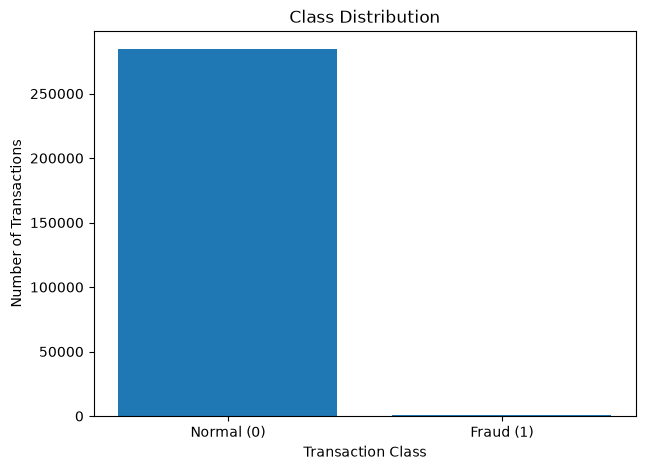

In [49]:
import matplotlib.pyplot as plt

class_counts = df["Class"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(["Normal (0)", "Fraud (1)"], class_counts.values)
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.title("Class Distribution")
plt.show()

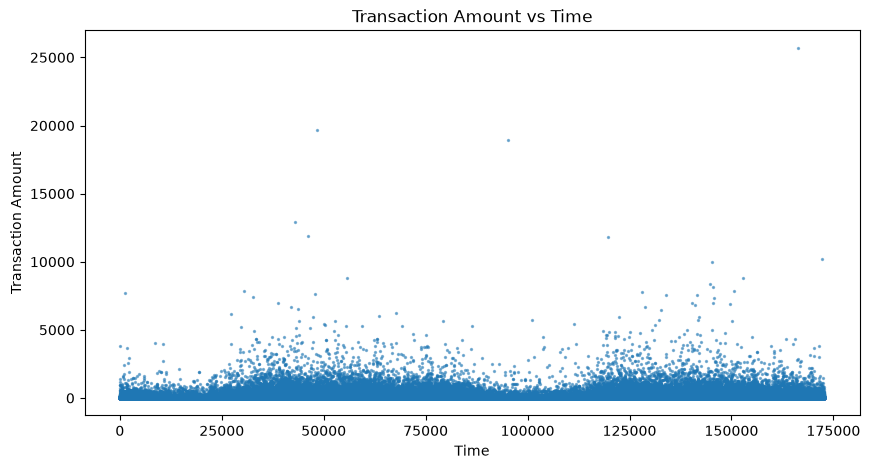

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(df["Time"], df["Amount"], s=2, alpha=0.5)

plt.xlabel("Time")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount vs Time")

plt.show()

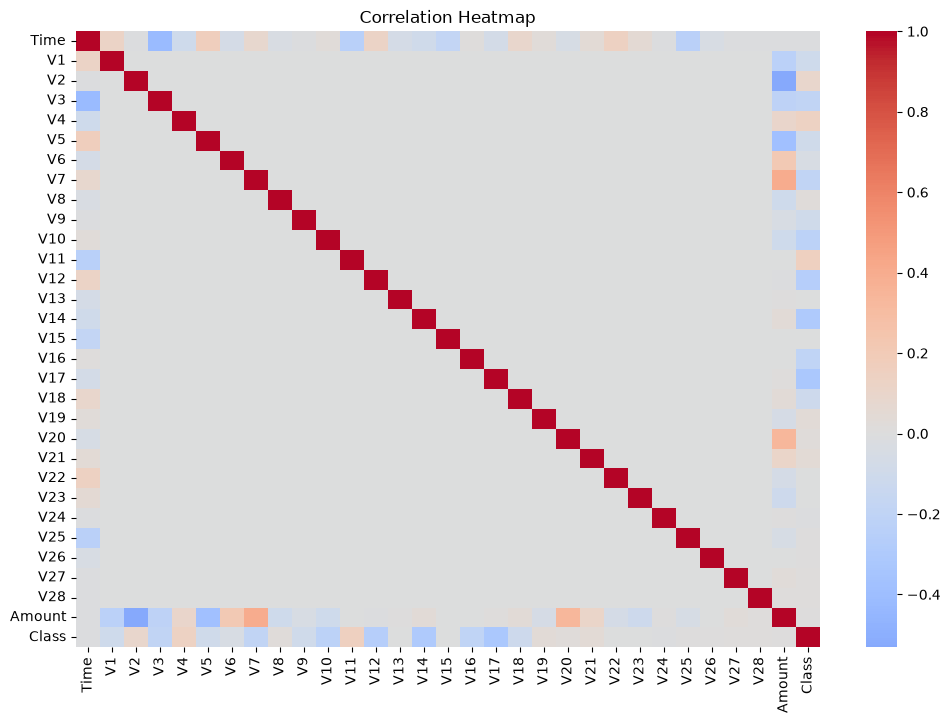

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [52]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression (Class Weight)",
        "Logistic Regression (SMOTE)",
        "Random Forest"
    ],
    "Accuracy": [0.9992, None, None, 0.9995],
    "Precision": [0.8289, 0.0610, 0.0580, 0.9059],
    "Recall": [0.6429, 0.9184, 0.9184, 0.7857],
    "F1-Score": [0.7241, 0.1144, 0.1092, 0.8415],
    "ROC-AUC": [0.9559, 0.9722, 0.9699, 0.9573]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.9559
1,Logistic Regression (Class Weight),NaN,0.0610,0.9184,0.1144,0.9722
2,Logistic Regression (SMOTE),NaN,0.0580,0.9184,0.1092,0.9699
3,Random Forest,0.9995,0.9059,0.7857,0.8415,0.9573


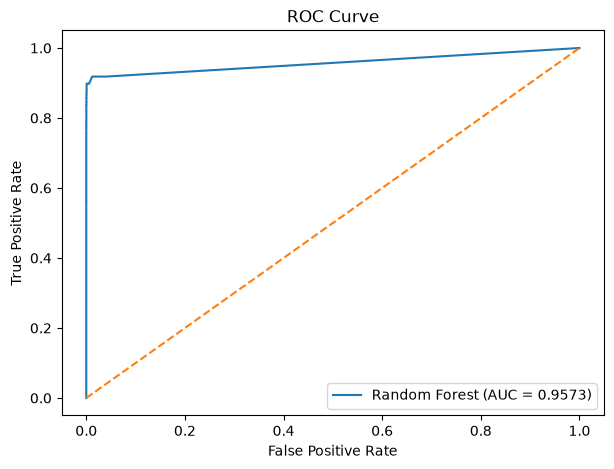

In [53]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

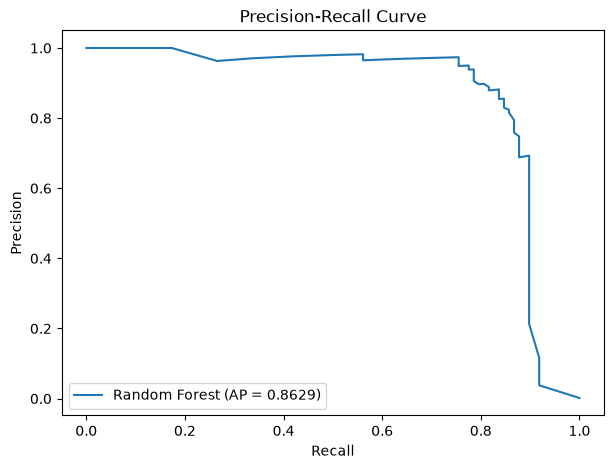

In [54]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision, recall, _ = precision_recall_curve(y_test, y_prob)
ap_score = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"Random Forest (AP = {ap_score:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

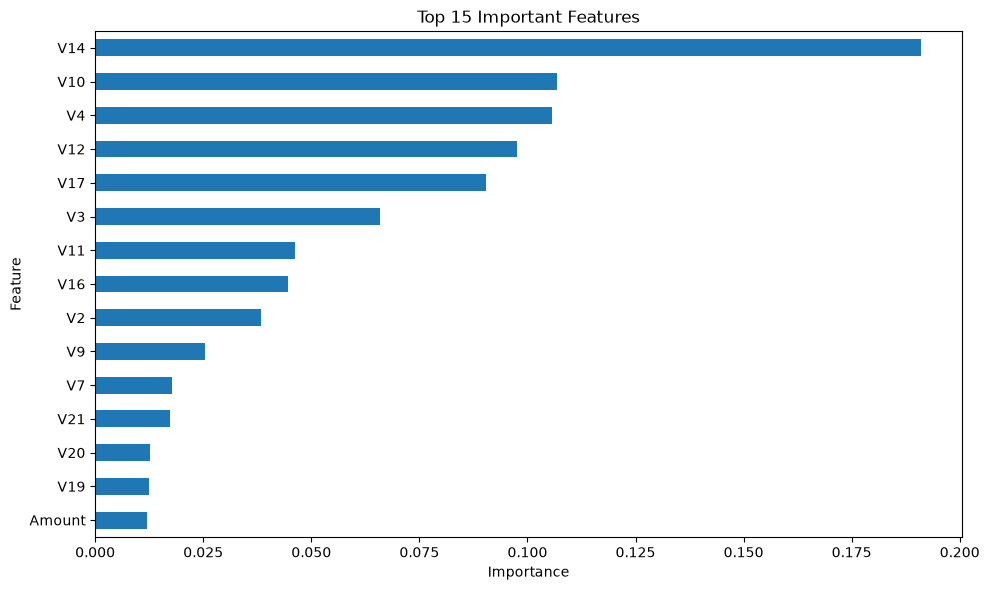

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
top_features.sort_values().plot(kind="barh")

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()

In [56]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1-Score": f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(results)

threshold_df

,Threshold,Precision,Recall,F1-Score
0,0.3,0.830000,0.846939,0.838384
1,0.4,0.880435,0.826531,0.852632
2,0.5,0.896552,0.795918,0.843243
3,0.6,0.950000,0.775510,0.853933
4,0.7,0.973684,0.755102,0.850575


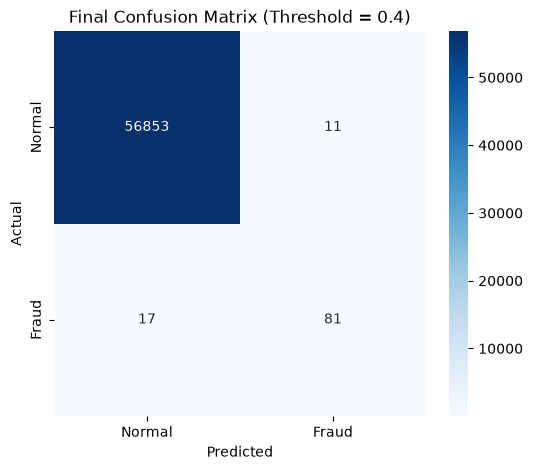

In [57]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

final_threshold = 0.4
y_final_pred = (y_prob >= final_threshold).astype(int)

cm = confusion_matrix(y_test, y_final_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Confusion Matrix (Threshold = 0.4)")
plt.show()